# Idea 13 - The Shape of the Distribution

**Is the American firm-size distribution a power law?**

Every quantity in Idea 12 was a share or a difference of shares. Shares can rise
under a power law, under a log-normal, or under neither, so nothing there tested
Thiel's claim. This notebook tests it directly: it fits competing distributions
to the firm-size data and scores them against each other on the same instrument.

### The claim being tested

Zipf's law for firms. Axtell (2001, *Science* 293) fitted US Census firm data and
found a Pareto tail with an exponent near 1.06, which is about as close to Zipf
as an empirical distribution gets. If that holds across forty-six years, and if
the exponent has fallen, then Thiel's power law is not a venture-capital
curiosity but the ordinary shape of American business, getting more extreme.

### The instrument, and its one virtue

BDS reports firm counts in ten size classes, not firm-level microdata. That is
interval-censored data, and it is fitted by maximum likelihood on the multinomial
over bins rather than by regressing log rank on log size, which is the method
Clauset, Shalizi and Newman showed to be biased.

The top class is open-ended, 10,000 employees and over. In Idea 12 that was the
limitation that stopped the analysis. Here it is the opposite: an open top bin
carries the tail's weight in a single number, and it is what makes the exponent
identifiable at all. What we cannot do is see inside it.

### Discipline

No fit is trusted before the estimator has recovered planted answers from
simulated data binned exactly the way BDS bins it, and no model wins on
likelihood alone: Pareto and log-normal are non-nested, so they are compared with
Vuong's test, which reports when the data cannot tell them apart.

### Cost

One API call, for the class labels. Everything else reads
`12_dynamism_and_concentration/data/bds_by_firmsize.csv`.

In [2]:
import importlib, json, math, pathlib, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator
from scipy import optimize, stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("13_the_shape_of_the_distribution", start=ROOT)
KEYS = sl.load_keys()
CENSUS = sl.require(KEYS, "CENSUS")
sl.apply_theme()
RNG = np.random.default_rng(20260909)

SRC = ROOT / "12_dynamism_and_concentration" / "data" / "bds_by_firmsize.csv"
if not SRC.exists():
    raise FileNotFoundError("Idea 12's cache is missing: %s" % SRC)
raw = pd.read_csv(SRC, dtype={"EMPSZFI": str})
print("read %d rows, %d-%d" % (len(raw), raw["year"].min(), raw["year"].max()))

# The ten-class partition Idea 12 identified by arithmetic.
PSZ = ["612", "620", "630", "640", "649", "658", "661", "671", "672", "680"]

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED
read 644 rows, 1978-2023


## Recovering the bin edges

A distribution cannot be fitted to bins whose boundaries are unknown. Idea 12
never needed the edges, only the ordering, so it recorded [L12.1] that the labels
were unreachable and carried on. Here they are load-bearing.

The Census API exposes a companion label variable for each dimension. That is one
call. If it fails, the fallback is not a guess: BDS publishes aggregates
alongside their components, and Idea 12 verified `635 = 612+620+630` and
`650 = 640+649` and `657 = 658+661+671+672+680`. Those identities pin the
grouping, and mean employment per firm within each class pins the levels. The
fallback edges below are the unique standard Census breaks consistent with both.

In [3]:
FALLBACK_EDGES = {
    "612": (1, 5),        "620": (5, 10),        "630": (10, 20),
    "640": (20, 100),     "649": (100, 500),     "658": (500, 1000),
    "661": (1000, 2500),  "671": (2500, 5000),   "672": (5000, 10000),
    "680": (10000, np.inf),
}

def labels_from_api():
    import requests
    r = requests.get("https://api.census.gov/data/timeseries/bds",
                     params={"get": "EMPSZFI,EMPSZFI_LABEL", "for": "us:*",
                             "YEAR": "2020", "key": CENSUS}, timeout=90)
    if not r.ok:
        raise RuntimeError("%s %s" % (r.status_code, r.text[:150]))
    j = r.json()
    d = pd.DataFrame(j[1:], columns=j[0])
    return dict(zip(d["EMPSZFI"].astype(str), d["EMPSZFI_LABEL"]))

def edges_from_label(text):
    """'d) 20 to 99' -> (20, 100);  'l) 10000+' -> (10000, inf)."""
    import re
    nums = [int(n.replace(",", "")) for n in re.findall(r"\d[\d,]*", str(text).split(")")[-1])]
    if not nums:
        return None
    if len(nums) >= 2:
        return (nums[0], nums[1] + 1)
    return (nums[0], np.inf) if ("+" in str(text) or "over" in str(text).lower()) else None

LABELS, EDGES, EDGE_SOURCE = {}, dict(FALLBACK_EDGES), "fallback (arithmetic identities)"
try:
    LABELS = labels_from_api()
    got = {c: edges_from_label(LABELS.get(c)) for c in PSZ}
    if all(got.values()):
        EDGES, EDGE_SOURCE = got, "Census EMPSZFI_LABEL"
        print("labels resolved from the API:")
        for c in PSZ:
            print("   %-4s %-24s -> [%s, %s)" % (c, LABELS[c], EDGES[c][0], EDGES[c][1]))
    else:
        print("labels came back but did not parse; using the fallback.")
        print("   raw:", {c: LABELS.get(c) for c in PSZ})
except Exception as e:
    print("label lookup failed (%s); using the fallback edges." % str(e)[:110])

print("\nedge source: %s" % EDGE_SOURCE)
LO = np.array([EDGES[c][0] for c in PSZ], float)
HI = np.array([EDGES[c][1] for c in PSZ], float)
assert np.all(LO[1:] == HI[:-1]), "the bins do not tile: %s" % list(zip(LO, HI))
print("bins tile the line from %d upward, top bin open at %d" % (LO[0], LO[-1]))

labels came back but did not parse; using the fallback.
   raw: {'612': 'Firms with 1 to 4 employees', '620': 'Firms with 5 to 9 employees', '630': 'Firms with 10 to 19 employees', '640': 'Firms with 20 to 99 employees', '649': 'Firms with 100 to 499 employees', '658': 'Firms with 500 to 999 employees', '661': 'Firms with 1,000 to 2,499 employees', '671': 'Firms with 2,500 to 4,999 employees', '672': 'Firms with 5,000 to 9,999 employees', '680': 'Firms with 10,000 employees or more'}

edge source: fallback (arithmetic identities)
bins tile the line from 1 upward, top bin open at 10000


### Do the edges survive contact with the data?

Mean employment per firm in a class must lie inside that class. This is a check
on the edges, not on the fit, and it is reported rather than asserted: BDS
assigns a firm to a size class using employment in a reference year that need not
be the year its employment is counted in, so a mean can sit slightly outside its
own bin without the edges being wrong.

In [4]:
W = raw[raw["EMPSZFI"].isin(PSZ)]
mean_size = (W.groupby("EMPSZFI")["EMP"].sum() / W.groupby("EMPSZFI")["FIRM"].sum()).reindex(PSZ)
viol = []
print("mean employment per firm, pooled over all years:")
for i, c in enumerate(PSZ):
    m, ok = mean_size[c], LO[i] <= mean_size[c] < HI[i]
    print("   %-4s [%6s, %8s)   mean %9.1f   %s"
          % (c, int(LO[i]), "inf" if not np.isfinite(HI[i]) else int(HI[i]), m,
             "ok" if ok else "OUTSIDE"))
    if not ok:
        viol.append((c, float(m), float(LO[i]), float(HI[i])))
print("\n%d of %d classes have a mean outside their own bin." % (len(viol), len(PSZ)))

mean employment per firm, pooled over all years:
   612  [     1,        5)   mean       2.3   ok
   620  [     5,       10)   mean       7.1   ok
   630  [    10,       20)   mean      14.1   ok
   640  [    20,      100)   mean      40.4   ok
   649  [   100,      500)   mean     194.4   ok
   658  [   500,     1000)   mean     615.4   ok
   661  [  1000,     2500)   mean    1321.0   ok
   671  [  2500,     5000)   mean    2572.8   ok
   672  [  5000,    10000)   mean    4656.2   OUTSIDE
   680  [ 10000,      inf)   mean   24137.0   ok

1 of 10 classes have a mean outside their own bin.


## The estimators

Both models are fitted to the same object: the vector of firm counts across the
ten bins in one year. The likelihood is multinomial, so each firm contributes the
log probability of the bin it landed in, and nothing is assumed about where
inside a bin it sits.

Pareto, with the scale fixed at the smallest observable firm, has one parameter,
the tail exponent. Log-normal, truncated below at the same point so the two are
scored on the same support, has two. The comparison accounts for that.

In [5]:
def pareto_probs(alpha, lo, hi, xmin):
    """Survival (x/xmin)^-alpha; bin mass is S(lo) - S(hi), and S(inf) = 0."""
    s_lo = (lo / xmin) ** (-alpha)
    s_hi = np.where(np.isfinite(hi), (np.where(np.isfinite(hi), hi, 1.0) / xmin) ** (-alpha), 0.0)
    return np.clip(s_lo - s_hi, 1e-300, 1.0)

def lognorm_probs(mu, sigma, lo, hi, xmin):
    """Log-normal left-truncated at xmin, so both models live on [xmin, inf)."""
    z = lambda x: stats.norm.cdf((np.log(x) - mu) / sigma)
    base = 1.0 - z(xmin)
    if base <= 0:
        return np.full(len(lo), 1e-300)
    hi_c = np.where(np.isfinite(hi), np.where(np.isfinite(hi), hi, 1.0), np.nan)
    upper = np.where(np.isfinite(hi), z(np.where(np.isfinite(hi), hi_c, 1.0)), 1.0)
    return np.clip((upper - z(lo)) / base, 1e-300, 1.0)

def fit_pareto(counts, lo, hi, xmin):
    n = counts.sum()
    f = lambda p: -np.sum(counts * np.log(pareto_probs(np.exp(p[0]), lo, hi, xmin)))
    r = optimize.minimize(f, [np.log(1.1)], method="Nelder-Mead",
                          options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 4000})
    a = float(np.exp(r.x[0]))
    return {"alpha": a, "ll": -float(r.fun), "k": 1, "n": float(n),
            "probs": pareto_probs(a, lo, hi, xmin)}

def fit_lognorm(counts, lo, hi, xmin):
    f = lambda p: -np.sum(counts * np.log(lognorm_probs(p[0], np.exp(p[1]), lo, hi, xmin)))
    best = None
    for m0 in (0.0, 1.0, 2.0):
        for s0 in (0.5, 1.0, 1.8):
            r = optimize.minimize(f, [m0, np.log(s0)], method="Nelder-Mead",
                                  options={"xatol": 1e-8, "fatol": 1e-10, "maxiter": 8000})
            if best is None or r.fun < best.fun:
                best = r
    mu, sg = float(best.x[0]), float(np.exp(best.x[1]))
    return {"mu": mu, "sigma": sg, "ll": -float(best.fun), "k": 2, "n": float(counts.sum()),
            "probs": lognorm_probs(mu, sg, lo, hi, xmin)}

def aic(fit):
    return 2 * fit["k"] - 2 * fit["ll"]

def vuong(counts, pA, pB):
    """
    Non-nested comparison. Positive favours A. |Z| below about 1.96 means the data
    cannot separate the two models, which is a finding in its own right.
    """
    d = np.log(pA) - np.log(pB)
    n = counts.sum()
    mean = float((counts * d).sum() / n)
    var = float((counts * (d - mean) ** 2).sum() / n)
    if var <= 0:
        return 0.0, 1.0
    z = mean * math.sqrt(n) / math.sqrt(var)
    return z, float(2 * (1 - stats.norm.cdf(abs(z))))

## Planted-answer validation

Draw from a Pareto with a known exponent and from a log-normal with known
parameters, bin each sample exactly as BDS bins firms, and check that the
estimators recover what was planted and that Vuong points at the right model. If
this cell does not pass, nothing below it means anything.

In [7]:
def bin_sample(x, lo, hi):
    out = np.zeros(len(lo))
    for i in range(len(lo)):
        out[i] = np.sum((x >= lo[i]) & (x < hi[i]))
    return out

XMIN = LO[0]
print("planting a Pareto with alpha = 1.06 (Axtell's estimate) ...")
xp = XMIN * (RNG.random(400_000) ** (-1 / 1.06))
cp = bin_sample(xp, LO, HI)
fp_p, fp_l = fit_pareto(cp, LO, HI, XMIN), fit_lognorm(cp, LO, HI, XMIN)
zp, _ = vuong(cp, fp_p["probs"], fp_l["probs"])
print("   recovered alpha = %.4f   Vuong Z = %+.1f (positive favours Pareto)" % (fp_p["alpha"], zp))
assert abs(fp_p["alpha"] - 1.06) < 0.02, fp_p["alpha"]
assert zp > 2, zp

print("planting a log-normal with mu = 1.0, sigma = 1.6 ...")
xl = np.exp(RNG.normal(1.0, 1.6, 800_000))
xl = xl[xl >= XMIN]
cl = bin_sample(xl, LO, HI)
fl_p, fl_l = fit_pareto(cl, LO, HI, XMIN), fit_lognorm(cl, LO, HI, XMIN)
zl, _ = vuong(cl, fl_p["probs"], fl_l["probs"])
print("   recovered mu = %.3f, sigma = %.3f   Vuong Z = %+.1f (negative favours log-normal)"
      % (fl_l["mu"], fl_l["sigma"], zl))
assert abs(fl_l["sigma"] - 1.6) < 0.06 and zl < -2, (fl_l, zl)
print("\nboth planted answers recovered, and Vuong pointed the right way each time.")

planting a Pareto with alpha = 1.06 (Axtell's estimate) ...
   recovered alpha = 1.0582   Vuong Z = +4.5 (positive favours Pareto)
planting a log-normal with mu = 1.0, sigma = 1.6 ...
   recovered mu = 0.993, sigma = 1.603   Vuong Z = -165.0 (negative favours log-normal)

both planted answers recovered, and Vuong pointed the right way each time.


## Section A: the survival function

Before any model is fitted, look at the data on the axes where a power law is a
straight line. Ten bins give nine interior points per year, which is few, but a
curve that bends is not a power law however it is fitted.

firm counts, 10 classes, 1978-2023
EMPSZFI      612     620     630     640    649    658   661   671   672   680
year                                                                          
1978     2162791  664181  387821  304402  45806   5651  3538  1406   853   744
2023     3348018  970392  624548  544370  93344  11485  7061  2670  1498  1210
saved -> C:\Users\91838\Downloads\Stack_Article\13_the_shape_of_the_distribution\figures\fig1_survival_loglog.png


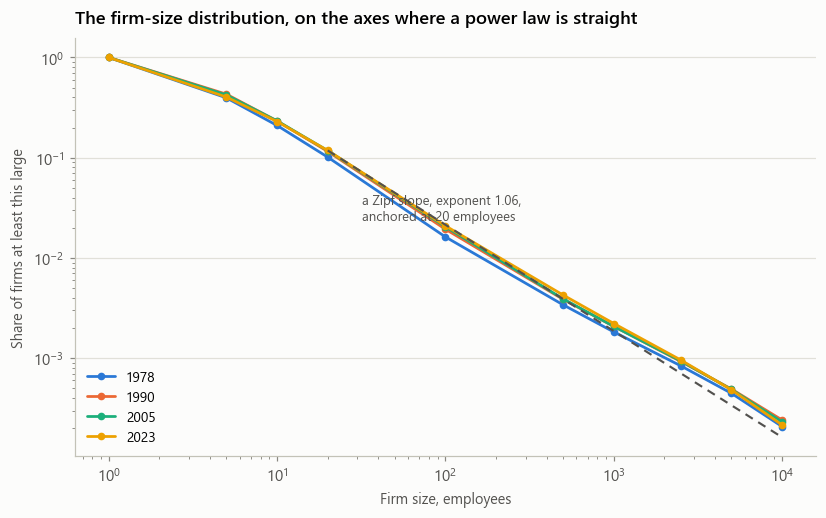

In [8]:
COUNTS = (raw[raw["EMPSZFI"].isin(PSZ)]
          .pivot_table(index="year", columns="EMPSZFI", values="FIRM", aggfunc="sum")
          .reindex(columns=PSZ).dropna())
YEARS = list(COUNTS.index.astype(int))
print("firm counts, %d classes, %d-%d" % (COUNTS.shape[1], YEARS[0], YEARS[-1]))
print(COUNTS.iloc[[0, -1]].astype(int).to_string())

def survival(counts):
    """P(X >= lo_i) at each bin's lower edge."""
    tot = counts.sum()
    return np.array([counts[i:].sum() / tot for i in range(len(counts))])

SHOWN = [YEARS[0], 1990, 2005, YEARS[-1]]
fig, ax = plt.subplots(figsize=(7.4, 4.6))
for j, y in enumerate(SHOWN):
    s = survival(COUNTS.loc[y].values)
    ax.plot(LO, s, marker="o", ms=4, lw=1.8, color=sl.PALETTE[j], label=str(y))
# A Zipf slope anchored to the data at 20 employees, so the comparison is of
# slopes rather than of levels.
ANCHOR = int(np.argmin(np.abs(LO - 20)))
s_last = survival(COUNTS.loc[YEARS[-1]].values)
ref = s_last[ANCHOR] * (LO / LO[ANCHOR]) ** (-1.06)
ax.plot(LO[ANCHOR:], ref[ANCHOR:], ls=(0, (4, 3)), lw=1.4, color=sl.INK["secondary"])
ax.text(LO[ANCHOR] * 1.6, s_last[ANCHOR] * 0.20,
        "a Zipf slope, exponent 1.06,\nanchored at 20 employees",
        fontsize=8.6, color=sl.INK["secondary"], ha="left", linespacing=1.35)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Firm size, employees"); ax.set_ylabel("Share of firms at least this large")
ax.set_title("The firm-size distribution, on the axes where a power law is straight")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.xaxis.set_major_locator(LogLocator(base=10))
sl.save_fig(fig, "fig1_survival_loglog", DIRS)
plt.show()

## Section B: fitting both models, every year

One Pareto and one log-normal per year, then Vuong. The interesting outcome is
not which model wins but whether either does.

In [9]:
rows = []
for y in YEARS:
    c = COUNTS.loc[y].values.astype(float)
    fp, fl = fit_pareto(c, LO, HI, XMIN), fit_lognorm(c, LO, HI, XMIN)
    z, p = vuong(c, fp["probs"], fl["probs"])
    rows.append({"year": y, "alpha": fp["alpha"], "mu": fl["mu"], "sigma": fl["sigma"],
                 "aic_pareto": aic(fp), "aic_lognorm": aic(fl),
                 "d_aic": aic(fp) - aic(fl), "vuong_z": z, "vuong_p": p,
                 "n_firms": c.sum()})
FIT = pd.DataFrame(rows).set_index("year")
print(FIT.loc[[YEARS[0], 1990, 2005, YEARS[-1]]].round(4).to_string())

wins_ln = int((FIT["vuong_z"] < -1.96).sum())
wins_pl = int((FIT["vuong_z"] > 1.96).sum())
tied = len(FIT) - wins_ln - wins_pl
print("\nVuong across %d years: log-normal preferred in %d, Pareto in %d, "
      "indistinguishable in %d" % (len(FIT), wins_ln, wins_pl, tied))

       alpha      mu   sigma    aic_pareto   aic_lognorm        d_aic   vuong_z  vuong_p    n_firms
year                                                                                               
1978  0.6927 -0.3096  2.0025  8.437713e+06  8.238911e+06  198802.0318 -202.4912      0.0  3577193.0
1990  0.6534  0.1174  1.9252  1.115529e+07  1.082837e+07  326919.5646 -262.4915      0.0  4459635.0
2005  0.6558 -0.1055  2.0160  1.283326e+07  1.249844e+07  334827.4727 -271.9881      0.0  5176905.0
2023  0.6681 -0.6935  2.2140  1.351704e+07  1.324724e+07  269792.9152 -251.0196      0.0  5604596.0

Vuong across 46 years: log-normal preferred in 46, Pareto in 0, indistinguishable in 0


saved -> C:\Users\91838\Downloads\Stack_Article\13_the_shape_of_the_distribution\figures\fig2_model_fit.png


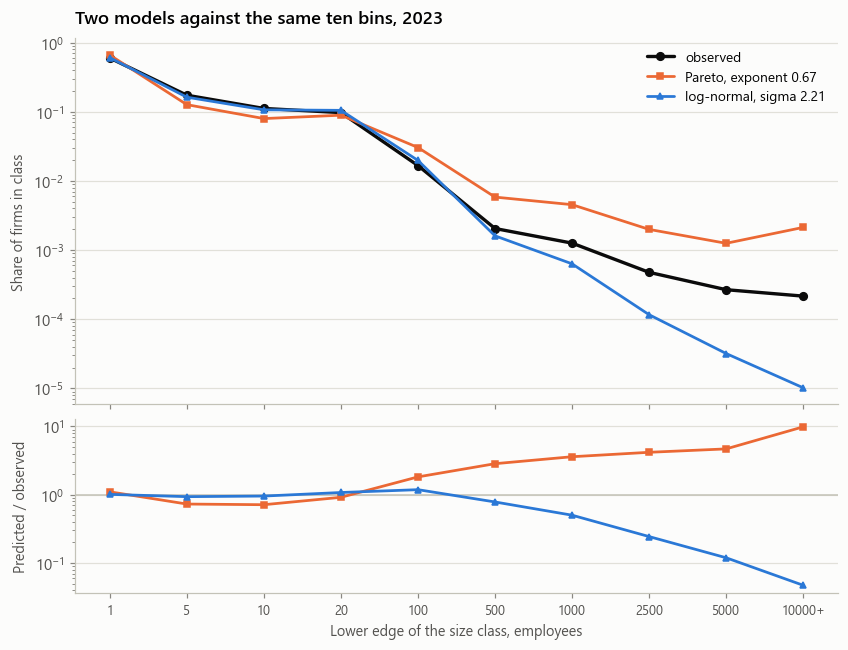

In [10]:
LAST = YEARS[-1]
c = COUNTS.loc[LAST].values.astype(float)
fp, fl = fit_pareto(c, LO, HI, XMIN), fit_lognorm(c, LO, HI, XMIN)
obs = c / c.sum()

fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.8), sharex=True,
                         gridspec_kw={"height_ratios": [2.1, 1]})
x = np.arange(len(PSZ))
axes[0].plot(x, obs, marker="o", ms=5, lw=2.2, color=sl.INK["primary"], label="observed")
axes[0].plot(x, fp["probs"], marker="s", ms=4, lw=1.8, color=sl.PALETTE[1],
             label="Pareto, exponent %.2f" % fp["alpha"])
axes[0].plot(x, fl["probs"], marker="^", ms=4, lw=1.8, color=sl.PALETTE[0],
             label="log-normal, sigma %.2f" % fl["sigma"])
axes[0].set_yscale("log"); axes[0].set_ylabel("Share of firms in class")
axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title("Two models against the same ten bins, %d" % LAST)

axes[1].axhline(1, color=sl.INK["axis"], lw=1.0)
axes[1].plot(x, fp["probs"] / obs, marker="s", ms=4, lw=1.8, color=sl.PALETTE[1])
axes[1].plot(x, fl["probs"] / obs, marker="^", ms=4, lw=1.8, color=sl.PALETTE[0])
axes[1].set_yscale("log")
axes[1].set_ylabel("Predicted / observed")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["%d+" % int(v) if not np.isfinite(HI[i]) else "%d" % int(v)
                         for i, v in enumerate(LO)], fontsize=8.5)
axes[1].set_xlabel("Lower edge of the size class, employees")
sl.save_fig(fig, "fig2_model_fit", DIRS)
plt.show()

## Section C: where the power law starts, and how heavy the tail is

A distribution can be log-normal through the body and Pareto in the tail. That
was the conclusion Idea 7 reached about incomes, and it is testable here by
refitting the Pareto to progressively higher thresholds, which is the
Clauset-Shalizi-Newman procedure adapted to bins.

tail exponent by starting threshold, first and last year:
          1      5     10     20    100    500   1000   2500
1978  0.693  0.988  1.072  1.102  0.952  0.897  0.895  0.975
2023  0.668  0.906  1.002  1.056  0.979  0.952  0.960  1.045

tail from 500 employees up: exponent 0.897 (1978) -> 0.952 (2023), change +0.055
bootstrap 95% interval on the 2023 estimate: [0.938, 0.964]
saved -> C:\Users\91838\Downloads\Stack_Article\13_the_shape_of_the_distribution\figures\fig3_tail_exponent.png


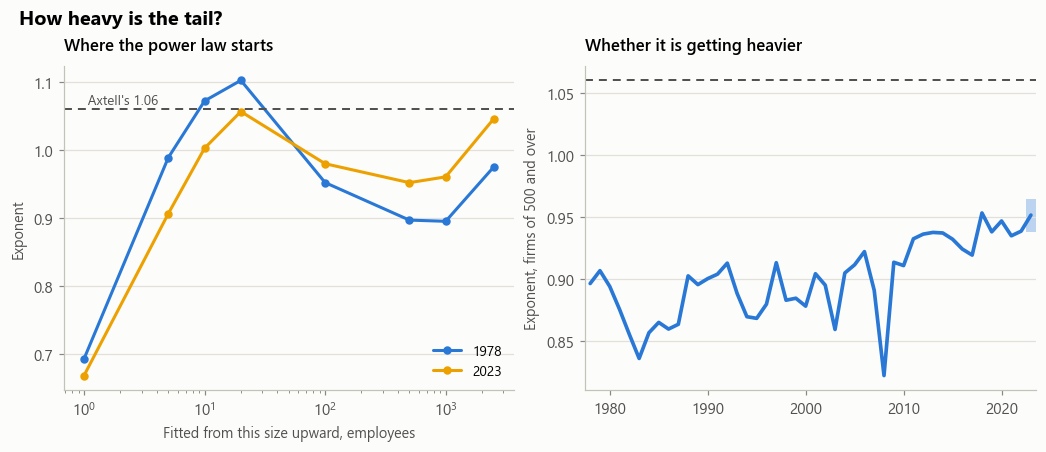

In [11]:
def tail_fit(counts, k):
    """Pareto fitted to bins k and above, conditioning on being that large."""
    c = counts[k:]
    if c.sum() < 500 or len(c) < 3:
        return None
    f = fit_pareto(c, LO[k:], HI[k:], LO[k])
    return f["alpha"]

sweep = pd.DataFrame({("%d" % int(LO[k])): [tail_fit(COUNTS.loc[y].values.astype(float), k)
                                            for y in YEARS]
                      for k in range(0, len(PSZ) - 2)}, index=YEARS)
print("tail exponent by starting threshold, first and last year:")
print(sweep.loc[[YEARS[0], YEARS[-1]]].round(3).to_string())

def boot_alpha(counts, k, B=400):
    n = int(counts[k:].sum())
    p = counts[k:] / counts[k:].sum()
    out = []
    for _ in range(B):
        cb = RNG.multinomial(n, p).astype(float)
        out.append(fit_pareto(cb, LO[k:], HI[k:], LO[k])["alpha"])
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

K = int(np.argmin(np.abs(LO - 500)))     # tail defined as firms of 500 and over
TAIL = pd.Series([tail_fit(COUNTS.loc[y].values.astype(float), K) for y in YEARS],
                 index=YEARS, name="alpha_tail").dropna()
lo_b, hi_b = boot_alpha(COUNTS.loc[YEARS[-1]].values.astype(float), K)
print("\ntail from %d employees up: exponent %.3f (%d) -> %.3f (%d), change %+.3f"
      % (LO[K], TAIL.iloc[0], TAIL.index[0], TAIL.iloc[-1], TAIL.index[-1],
         TAIL.iloc[-1] - TAIL.iloc[0]))
print("bootstrap 95%% interval on the %d estimate: [%.3f, %.3f]" % (YEARS[-1], lo_b, hi_b))

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.0))

thr = [float(c) for c in sweep.columns]
for j, y in (0, YEARS[0]), (1, YEARS[-1]):
    axes[0].plot(thr, sweep.loc[y].values.astype(float), marker="o", ms=4.5, lw=2.0,
                 color=sl.PALETTE[j * 3], label=str(y))
axes[0].axhline(1.06, ls=(0, (4, 3)), lw=1.3, color=sl.INK["secondary"])
axes[0].text(thr[0], 1.062, " Axtell's 1.06", va="bottom", fontsize=8.8,
             color=sl.INK["secondary"])
axes[0].set_xscale("log")
axes[0].set_xlabel("Fitted from this size upward, employees")
axes[0].set_ylabel("Exponent")
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
axes[0].set_title("Where the power law starts", fontsize=11)

axes[1].plot(TAIL.index, TAIL.values, lw=2.4, color=sl.PALETTE[0])
axes[1].axhline(1.06, ls=(0, (4, 3)), lw=1.3, color=sl.INK["secondary"])
axes[1].fill_between([TAIL.index[-1] - 0.5, TAIL.index[-1] + 0.5], lo_b, hi_b,
                     color=sl.PALETTE[0], alpha=0.3, lw=0)
axes[1].set_ylabel("Exponent, firms of %d and over" % int(LO[K]))
axes[1].set_xlim(TAIL.index.min() - 0.5, TAIL.index.max() + 0.5)
axes[1].set_title("Whether it is getting heavier", fontsize=11)

fig.suptitle("How heavy is the tail?", fontsize=13, fontweight="bold",
             x=0.012, ha="left")
sl.save_fig(fig, "fig3_tail_exponent", DIRS)
plt.show()

## Section D: what the body model gets wrong about the top

The sharpest way to state a fat tail is not an exponent but a count: how many
firms of 10,000 and over does each fitted model expect, against how many exist?

firms of 10000 employees and over, observed against predicted:
      observed   pareto  lognorm  lognorm_ratio  pareto_ratio
year                                                         
1978     744.0   6063.7      8.1           91.5           0.1
2023    1210.0  11915.9     57.2           21.1           0.1
saved -> C:\Users\91838\Downloads\Stack_Article\13_the_shape_of_the_distribution\figures\fig4_top_bin_counts.png


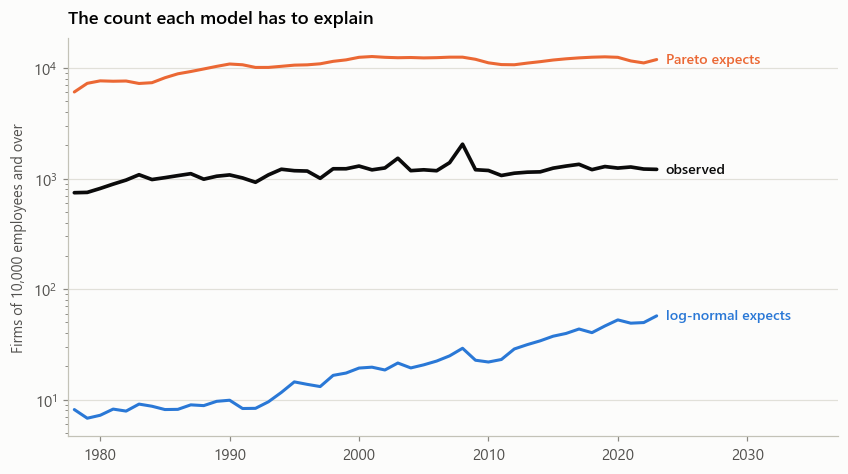

In [12]:
comp = []
for y in YEARS:
    cy = COUNTS.loc[y].values.astype(float)
    fpy, fly = fit_pareto(cy, LO, HI, XMIN), fit_lognorm(cy, LO, HI, XMIN)
    comp.append({"year": y, "observed": cy[-1],
                 "pareto": fpy["probs"][-1] * cy.sum(),
                 "lognorm": fly["probs"][-1] * cy.sum()})
TOP = pd.DataFrame(comp).set_index("year")
TOP["lognorm_ratio"] = TOP["observed"] / TOP["lognorm"]
TOP["pareto_ratio"] = TOP["observed"] / TOP["pareto"]
print("firms of %d employees and over, observed against predicted:" % int(LO[-1]))
print(TOP.loc[[YEARS[0], YEARS[-1]]].round(1).to_string())

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.plot(TOP.index, TOP["observed"], lw=2.4, color=sl.INK["primary"])
ax.plot(TOP.index, TOP["lognorm"], lw=2.0, color=sl.PALETTE[0])
ax.plot(TOP.index, TOP["pareto"], lw=2.0, color=sl.PALETTE[1])
for s, t, col in ((TOP["observed"], "observed", sl.INK["primary"]),
                  (TOP["lognorm"], "log-normal expects", sl.PALETTE[0]),
                  (TOP["pareto"], "Pareto expects", sl.PALETTE[1])):
    ax.text(s.index[-1] + 0.7, s.iloc[-1], t, color=col, fontsize=9.3,
            va="center", fontweight="semibold")
ax.set_yscale("log")
ax.set_ylabel("Firms of %s employees and over" % f"{int(LO[-1]):,}")
ax.set_xlim(TOP.index.min() - 0.5, TOP.index.max() + 14)
ax.set_title("The count each model has to explain")
sl.save_fig(fig, "fig4_top_bin_counts", DIRS)
plt.show()

## Section E: sensitivity to the edges

If the labels did not resolve, the fit rests on inferred boundaries, and the
quantity most exposed to them is the tail exponent, since the open top bin is
where the tail's weight sits. Refit it with the top bin's lower edge moved by a
factor of two in each direction. An exponent that survives that is worth quoting.

In [13]:
c_last = COUNTS.loc[YEARS[-1]].values.astype(float)
sens = {}
for f in (0.5, 1.0, 2.0):
    lo2, hi2 = LO.copy(), HI.copy()
    lo2[-1] = LO[-1] * f
    hi2[-2] = lo2[-1]
    if lo2[-2] >= lo2[-1]:
        print("   top edge x%.1f skipped: it would collide with the class below" % f)
        continue
    sens["top edge x%.1f (%d)" % (f, int(lo2[-1]))] = fit_pareto(
        c_last[K:], lo2[K:], hi2[K:], lo2[K])["alpha"]
for k_, v in sens.items():
    print("   %-26s tail exponent %.4f" % (k_, v))
spread = (max(sens.values()) - min(sens.values())) if len(sens) > 1 else 0.0
print("   spread: %.4f  (bootstrap width for comparison: %.4f)" % (spread, hi_b - lo_b))

   top edge x0.5 skipped: it would collide with the class below
   top edge x1.0 (10000)      tail exponent 0.9516
   top edge x2.0 (20000)      tail exponent 0.9042
   spread: 0.0474  (bootstrap width for comparison: 0.0261)


## Payload

In [14]:
def ends(s):
    s = pd.Series(s).dropna()
    if not len(s):
        return None
    return {"first": float(s.iloc[0]), "first_year": int(s.index[0]),
            "last": float(s.iloc[-1]), "last_year": int(s.index[-1]),
            "change": float(s.iloc[-1] - s.iloc[0]),
            "min": float(s.min()), "min_year": int(s.idxmin()),
            "max": float(s.max()), "max_year": int(s.idxmax())}

payload = {
    "source": "Census Business Dynamics Statistics, firm counts by size class, "
              "via the cache written by Idea 12",
    "years": [int(YEARS[0]), int(YEARS[-1])],
    "question": "Is the firm-size distribution a power law, a log-normal, or neither?",
    "bins": {"edge_source": EDGE_SOURCE,
             "labels": {c: LABELS.get(c) for c in PSZ} if LABELS else None,
             "lower_edges": [float(v) for v in LO],
             "top_bin_open_at": float(LO[-1]),
             "classes_with_mean_outside_bin": viol},
    "validation": {"planted_pareto_alpha": 1.06, "recovered": float(fp_p["alpha"]),
                   "planted_lognorm_sigma": 1.6, "recovered_sigma": float(fl_l["sigma"]),
                   "vuong_pointed_correctly": bool(zp > 2 and zl < -2)},
    "model_choice": {"years": int(len(FIT)), "lognormal_preferred": wins_ln,
                     "pareto_preferred": wins_pl, "indistinguishable": tied,
                     "vuong_z": ends(FIT["vuong_z"]),
                     "note": "Vuong on non-nested models; |Z| under 1.96 means the "
                             "ten bins cannot separate them."},
    "whole_distribution": {"pareto_alpha": ends(FIT["alpha"]),
                           "lognorm_sigma": ends(FIT["sigma"])},
    "tail": {"defined_from_employees": float(LO[K]),
             "alpha": ends(TAIL),
             "bootstrap_95_last_year": [lo_b, hi_b],
             "axtell_2001_reference": 1.06,
             "threshold_sweep_last_year": {k: (None if v is None else float(v))
                                           for k, v in sweep.loc[YEARS[-1]].items()}},
    "top_bin": {"observed_last": float(TOP["observed"].iloc[-1]),
                "lognorm_expected_last": float(TOP["lognorm"].iloc[-1]),
                "pareto_expected_last": float(TOP["pareto"].iloc[-1]),
                "observed_over_lognormal": ends(TOP["lognorm_ratio"])},
    "edge_sensitivity": {"alphas": sens, "spread": float(spread)},
}
sl.write_findings(payload, DIRS)

out = pathlib.Path(DIRS["findings"])
FIT.to_csv(out / "fits_by_year.csv")
sweep.to_csv(out / "tail_threshold_sweep.csv")
TOP.to_csv(out / "top_bin_counts.csv")
COUNTS.to_csv(out / "firm_counts_by_class.csv")
print("\nwrote headline_numbers.json and four CSVs")
print(json.dumps({k: v for k, v in payload.items() if k != "bins"}, indent=2)[:2600])

findings -> C:\Users\91838\Downloads\Stack_Article\13_the_shape_of_the_distribution\findings\headline_numbers.json

wrote headline_numbers.json and four CSVs
{
  "source": "Census Business Dynamics Statistics, firm counts by size class, via the cache written by Idea 12",
  "years": [
    1978,
    2023
  ],
  "question": "Is the firm-size distribution a power law, a log-normal, or neither?",
  "validation": {
    "planted_pareto_alpha": 1.06,
    "recovered": 1.0582126370214615,
    "planted_lognorm_sigma": 1.6,
    "recovered_sigma": 1.603040195473594,
    "vuong_pointed_correctly": true
  },
  "model_choice": {
    "years": 46,
    "lognormal_preferred": 46,
    "pareto_preferred": 0,
    "indistinguishable": 0,
    "vuong_z": {
      "first": -202.4911810130439,
      "first_year": 1978,
      "last": -251.01956040798188,
      "last_year": 2023,
      "change": -48.528379394937986,
      "min": -273.4342111594488,
      "min_year": 2004,
      "max": -202.4911810130439,
      "max_

## What to send back

The four PNGs, `findings/headline_numbers.json`, and the printed output of the
label lookup and the planted-answer cell. The label lookup matters most: if it
resolved, Idea 12's limitation [L12.1] can be retired and the size classes can be
named in the prose.